# Weekly BTC-settled covered calls using spot volatility

**Question.** Does adding seven-day realized volatility improve next-week upper-tail forecasts and covered-call decisions relative to a fitted 30-day spot-volatility baseline under identical hypothetical premiums?

**Decision.** Each Friday choose whether to cover a fraction of BTC already held by writing a hypothetical one-week BTC-settled call. Use expected BTC gain to choose the strike, then expected log wealth to size the position. The main figures measure simulated BTC wealth relative to holding. There are no observed option premiums, trades, or fills.

**Source.** Coin Metrics Community BTC archive, CC BY-NC 4.0. See [data provenance](data/README.md). We use daily BTC/USD reference prices and a lagged on-chain fee feature in a separate secondary comparison.

In [1]:
import hashlib
import json
import runpy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import norm

SEED = 600
FIG = Path("fig")
FIG.mkdir(exist_ok=True)
archive = runpy.run_path("scripts/fetch_covered_call.py")
archive_path, SHA256 = archive["DATA"], archive["SHA256"]

if hashlib.sha256(archive_path.read_bytes()).hexdigest() != SHA256:
    raise ValueError("Coin Metrics archive differs from the pinned version")

daily = pd.read_csv(archive_path, usecols=["time", "PriceUSD", "FeeTotNtv", "TxCnt"], parse_dates=["time"])
daily = daily.set_index("time").sort_index()
assert daily.index.is_unique
# PriceUSD labeled Thursday is the reference at Friday 00:00 UTC.
spot = daily.PriceUSD.rename("spot")
spot.index = spot.index + pd.Timedelta(days=1)
spot = spot.loc["2020-08-01":"2026-05-22"]
assert spot.index.equals(pd.date_range(spot.index.min(), spot.index.max(), freq="D"))
assert spot.notna().all() and (spot > 0).all()

daily_return = np.log(spot).diff()
last7 = np.sqrt(365 * daily_return.pow(2).rolling(7).mean())
last30 = np.sqrt(365 * daily_return.pow(2).rolling(30).mean())
# Aggregate fees per recorded transaction across seven days, with one additional day of lag.
fee = daily.FeeTotNtv.rolling(7).sum() / daily.TxCnt.rolling(7).sum()
fee.index = fee.index + pd.Timedelta(days=2)

fridays = spot.index[spot.index.dayofweek == 4]
windows = pd.DataFrame({
    "spot": spot.reindex(fridays), "r": np.log(spot.reindex(fridays)).diff().shift(-1),
    "rv7": last7.reindex(fridays), "rv30": last30.reindex(fridays),
    "fee": fee.reindex(fridays),
}).iloc[:-1].tail(292).copy()
windows["end"] = windows.index + pd.Timedelta(days=7)
assert len(windows) == 292 and windows.notna().all().all()
assert (windows[["rv7", "rv30", "fee"]] > 0).all().all()
assert (np.diff(windows.index) == np.timedelta64(7, "D")).all()
train, test = windows.iloc[:-52].copy(), windows.iloc[-52:].copy()
cutoff = test.index[0]
assert train.end.max() == cutoff and test.end.max() == spot.index.max()
print(f"Train: {len(train)} Fridays, {train.index.min().date()} to {train.index.max().date()}")
print(f"Holdout: {len(test)} Fridays, {cutoff.date()} to {test.index.max().date()}, ending {test.end.max().date()}")

Train: 240 Fridays, 2020-10-16 to 2025-05-16
Holdout: 52 Fridays, 2025-05-23 to 2026-05-15, ending 2026-05-22


## Data and split

Each observation covers Friday 00:00 UTC through the next Friday 00:00 UTC. The daily label in the archive is shifted to the timestamp at which the spot reference is measured. The on-chain feature uses seven completed daily fee and transaction totals and adds a full day of lag. Trailing volatilities summarize squared daily log returns in annualized units using 365 days, then enter the weekly scale model. Daily prices miss intraday variation, and the reference timestamp is the hypothetical settlement proxy. Weekly returns do not overlap. Nearby weeks can still have related volatility and decisions.

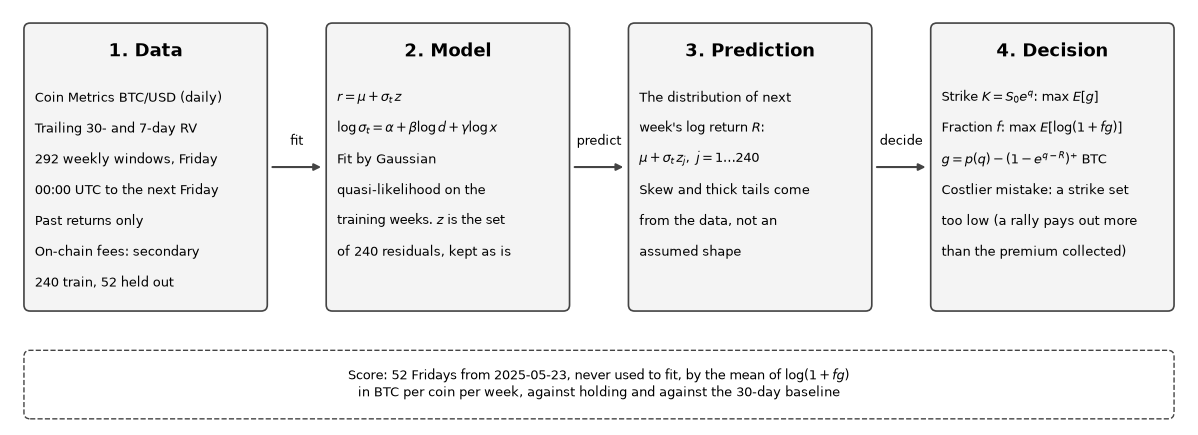

In [2]:
from matplotlib.patches import FancyBboxPatch

layers = [
    ("1. Data", [
        "Coin Metrics BTC/USD (daily)",
        "Trailing 30- and 7-day RV",
        "292 weekly windows, Friday",
        "00:00 UTC to the next Friday",
        "Past returns only",
        "On-chain fees: secondary",
        "240 train, 52 held out"]),
    ("2. Model", [
        r"$r = \mu + \sigma_t\, z$",
        r"$\log\sigma_t = \alpha + \beta\log d + \gamma\log x$",
        "Fit by Gaussian",
        "quasi-likelihood on the",
        "training weeks. $z$ is the set",
        "of 240 residuals, kept as is"]),
    ("3. Prediction", [
        "The distribution of next",
        "week's log return $R$:",
        r"$\mu + \sigma_t\, z_j,\ j = 1 \ldots 240$",
        "Skew and thick tails come",
        "from the data, not an",
        "assumed shape"]),
    ("4. Decision", [
        r"Strike $K = S_0 e^{q}$: max $E[g]$",
        r"Fraction $f$: max $E[\log(1 + f g)]$",
        r"$g = p(q) - (1 - e^{q-R})^{+}$ BTC",
        "Costlier mistake: a strike set",
        "too low (a rally pays out more",
        "than the premium collected)"]),
]
arrows = ["fit", "predict", "decide"]

fig, ax = plt.subplots(figsize=(15.2, 5.4))
ax.set_xlim(0, 15.2); ax.set_ylim(0, 5.4); ax.axis("off")
bw, gap, x0, top, bh = 3.1, 0.8, 0.2, 5.2, 3.7
for i, (title, body) in enumerate(layers):
    x = x0 + i * (bw + gap)
    ax.add_patch(FancyBboxPatch((x, top - bh), bw, bh, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc="#f4f4f4", ec="#444444", lw=1.2))
    ax.text(x + bw / 2, top - 0.35, title, ha="center", va="center", fontsize=13, fontweight="bold")
    for j, line in enumerate(body):
        ax.text(x + 0.12, top - 0.95 - 0.4 * j, line, ha="left", va="center", fontsize=9)
    if i < 3:
        ax.annotate("", xy=(x + bw + gap - 0.05, top - bh / 2), xytext=(x + bw + 0.05, top - bh / 2),
                    arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444"))
        ax.text(x + bw + gap / 2, top - bh / 2 + 0.25, arrows[i], ha="center", va="bottom", fontsize=9)
ax.add_patch(FancyBboxPatch((x0, 0.1), 4 * bw + 3 * gap, 0.85, boxstyle="round,pad=0.02,rounding_size=0.08",
                            fc="white", ec="#444444", lw=1.0, ls="--"))
ax.text(x0 + (4 * bw + 3 * gap) / 2, 0.525,
        f"Score: 52 Fridays from {cutoff.date()}, never used to fit, by the mean of $\\log(1 + f g)$\n"
        "in BTC per coin per week, against holding and against the 30-day baseline",
        ha="center", va="center", fontsize=9)
fig.savefig(FIG / "layers.png", dpi=150, bbox_inches="tight")
plt.show()

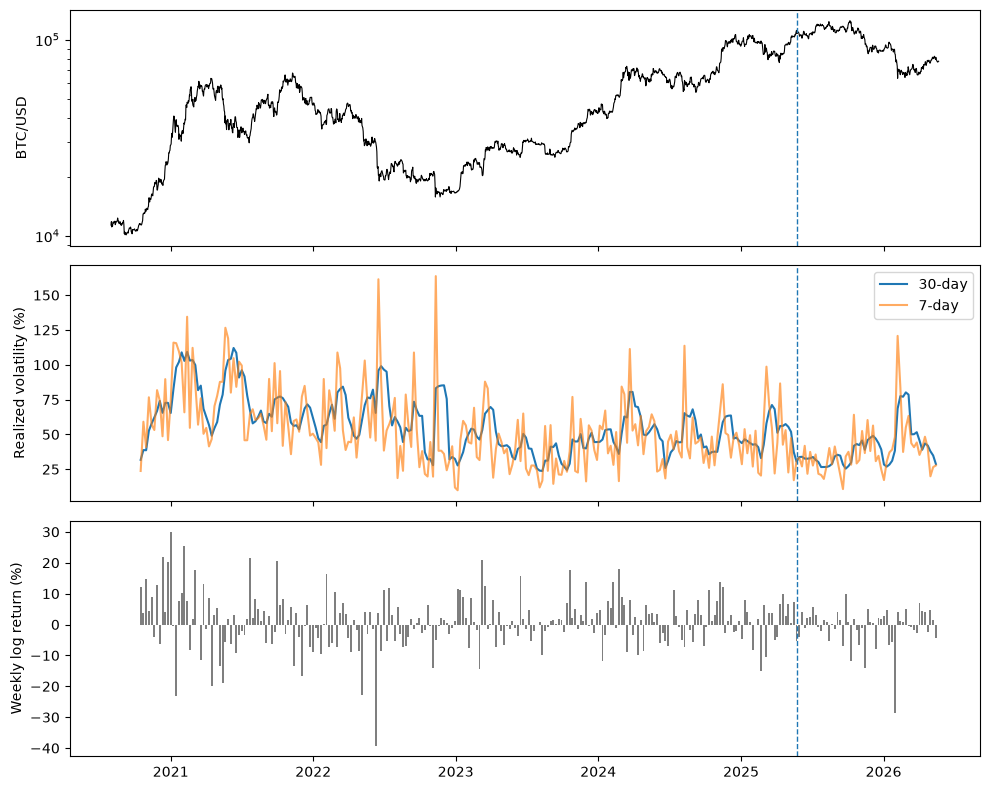

,r,rv7,rv30,fee
count,292.00000,292.00000,292.00000,292.00000
mean,0.00654,0.51390,0.54680,0.00010
std,0.08120,0.26320,0.19777,0.00014
min,-0.39222,0.09901,0.23739,0.00000
25%,-0.03435,0.32768,0.40184,0.00002
50%,0.00927,0.46004,0.51160,0.00005
75%,0.04506,0.62139,0.66931,0.00010
max,0.30100,1.63643,1.12050,0.00084


In [3]:
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(spot, color="black", lw=0.8)
ax[0].set_yscale("log")
ax[0].set_ylabel("BTC/USD")
ax[1].plot(windows.rv30 * 100, label="30-day")
ax[1].plot(windows.rv7 * 100, label="7-day", alpha=0.65)
ax[1].set_ylabel("Realized volatility (%)")
ax[1].legend()
ax[2].bar(windows.index, 100 * windows.r, width=5, color="tab:gray")
ax[2].set_ylabel("Weekly log return (%)")
for axis in ax:
    axis.axvline(cutoff, color="tab:blue", ls="--", lw=1)
fig.tight_layout()
fig.savefig(FIG / "raw_covered_call.png", dpi=150)
plt.show()
display(windows[["r", "rv7", "rv30", "fee"]].describe().round(5))

## Forecast model and validation

Use a location-scale model $R_t=\mu+\sigma_t z$. The baseline fits $\log\sigma_t=\alpha+\beta\log d_t$, where $d_t=\mathrm{RV}_{30,t}\sqrt{7/365}$. The full model adds $\gamma\log x_t$ with $x_t=\mathrm{RV}_{7,t}\sqrt{7/365}$. A secondary model adds the log of lagged on-chain BTC fees per transaction. Each fit uses Gaussian quasi-likelihood and then uses its training standardized residuals as the empirical distribution for $z$. The baseline and full model differ by one input.

The comparison uses the original design of 240 training and 52 held-out non-overlapping weeks. The earlier calendar reflects the availability of the pinned archive. The feature windows, forecast models, premium scenarios, q80 and q90 pinball losses, and four-week paired bootstrap blocks are fixed before scoring. An expanding-window check over the last 52 training Fridays compares q90 pinball losses without choosing a specification from the holdout.

In [4]:
T_WEEK = 7 / 365
for frame in (train, test):
    frame["d"] = frame.rv30 * np.sqrt(T_WEEK)
    frame["x"] = frame.rv7 * np.sqrt(T_WEEK)
BASE = "30-day baseline"
MODEL = "30-day + 7-day"
CHAIN = "Spot + lagged fees"
columns = {BASE: ("d",), MODEL: ("d", "x"), CHAIN: ("d", "x", "fee")}
fit_checks = []


def sigma_of(theta, frame, features):
    return np.exp(theta[1] + np.log(frame[list(features)].to_numpy()) @ theta[2:])


def fit_scale(frame, features):
    log_inputs = np.log(frame[list(features)].to_numpy())
    centers = log_inputs.mean(axis=0)
    design = np.column_stack([np.ones(len(frame)), log_inputs - centers])
    returns = frame.r.to_numpy()
    scale = 0.1  # numerical scaling of the drift coordinate

    def objective(params):
        residual = returns - scale * params[0]
        log_sigma = design @ params[1:]
        precision = np.exp(-2 * log_sigma)
        squared_z = residual**2 * precision
        loss = np.mean(log_sigma + 0.5 * squared_z)
        gradient = np.r_[-scale * np.mean(residual * precision),
                         design.T @ (1 - squared_z) / len(frame)]
        return loss, gradient

    start = np.r_[returns.mean() / scale, centers[0], 1.0, np.zeros(len(centers) - 1)]
    result = minimize(objective, start, jac=True, method="BFGS", options={"gtol": 1e-7})
    gradient_max = np.max(np.abs(result.jac))
    if not np.isfinite(result.fun) or not np.isfinite(gradient_max) or gradient_max > 1e-6:
        raise RuntimeError(f"Scale fit did not converge: {result.message}, gradient {gradient_max:.2g}")
    fit_checks.append(gradient_max)
    slopes = result.x[2:]
    return np.r_[scale * result.x[0], result.x[1] - centers @ slopes, slopes]


def forecast(training, evaluation, features):
    theta = fit_scale(training, features)
    z = (training.r.to_numpy() - theta[0]) / sigma_of(theta, training, features)
    draws = theta[0] + sigma_of(theta, evaluation, features)[:, None] * z
    return theta, z, draws


def pinball(draws, actual, quantile):
    err = np.asarray(actual) - np.quantile(draws, quantile, axis=1)
    return np.maximum(quantile * err, (quantile - 1) * err)


validation = {}
for name, features in columns.items():
    losses = []
    for i in range(len(train) - 52, len(train)):
        _, _, pred = forecast(train.iloc[:i], train.iloc[i:i + 1], features)
        losses.append(pinball(pred, train.r.iloc[i:i + 1], 0.90)[0])
    validation[name] = np.mean(losses)
display(pd.Series(validation, name="Training walk-forward q90 pinball loss"))

fitted = {name: forecast(train, test, features) for name, features in columns.items()}
draws = {name: result[2] for name, result in fitted.items()}
display(pd.DataFrame({name: pd.Series(result[0], index=["drift", "intercept", *columns[name]])
                      for name, result in fitted.items()}).round(5))

30-day baseline       0.011257
30-day + 7-day        0.011536
Spot + lagged fees    0.011015
Name: Training walk-forward q90 pinball loss, dtype: float64

,30-day baseline,30-day + 7-day,Spot + lagged fees
d,0.32274,0.40931,0.26448
drift,0.00964,0.00950,0.00786
fee,NaN,NaN,0.13118
intercept,-1.64961,-1.63907,-0.76961
x,NaN,-0.07826,-0.07505


## Payoff, strike and size

When $q=\log(K/S_0)$ and $R=\log(S_T/S_0)$, the BTC payout per BTC covered is $(1-e^{q-R})^+$. Define net gain $g=p(q)-c-(1-e^{q-R})^+$ with gross premium $p(q)$ and cost $c$. Choose $q$ to maximize expected $g$ over the grid. With a differentiable payoff expectation and no boundary, the marginal premium balances the marginal expected payout. For a Black–Scholes curve multiplied by $m$, this gives $mN(d_2)=E[e^{-R}\mathbf{1}\{R>q\}]$. A constant cost does not change that derivative; it changes whether writing is worthwhile. The empirical distribution and strike grid make this a discrete maximization.

For each selected strike choose $f\in[0,1]$ to maximize $E[\log(1+fg)]$. Holding gives $f=0$. Compare with the same strike at full and half coverage, and with fixed ATM and approximately 10% OTM full calls. Report half Kelly as half the model’s chosen fraction. Growth is the average realized weekly $\log(1+fg)$, with a separate exact conversion to simple sats or compounded BTC for communication.

**Pricing scenario.** Every model receives the same zero-rate Black–Scholes curve, based on 30-day realized spot volatility. The gross premium multipliers are 0.8, 1.0 and 1.2. Each main scenario deducts an illustrative 10,000 sats per BTC covered. The options market's implied volatility, tradable bids, spreads and exchange fees are unobserved.

In [5]:
Q = np.arange(0, 0.3001, 0.005)   # log strike offset, up to 35% above spot
F = np.linspace(0, 1, 101)        # fraction of the stack written


def premium(annual_vol, strike_grid=Q):
    '''Zero-rate Black–Scholes call premium in BTC per BTC covered.'''
    s = (np.asarray(annual_vol) * np.sqrt(T_WEEK))[:, None]
    d1 = (-strike_grid + 0.5 * s**2) / s
    return norm.cdf(d1) - np.exp(strike_grid) * norm.cdf(d1 - s)


def payout(q, r):
    '''Coin-settled payout, where q and r are log strike and price ratios.'''
    return -np.expm1(np.minimum(np.asarray(q) - np.asarray(r), 0))


def plan(annual_vol, R, *, prices, strike_grid=Q):
    '''Choose strike by expected gain, then fractional coverage by log growth.'''
    prem = prices
    expected = prem - payout(strike_grid[None, :, None], R[:, None, :]).mean(axis=2)
    eligible = prem > 0
    i = np.argmax(np.where(eligible, expected, -np.inf), axis=1)
    q, rows = strike_grid[i], np.arange(len(i))
    pr = prem[rows, i]
    cash_gain = pr[:, None] - payout(q[:, None], R)
    log_growth = np.log1p(F[None, :, None] * cash_gain[:, None, :]).mean(axis=2)
    can_write = eligible[rows, i] & (expected[rows, i] > 0)
    s = np.asarray(annual_vol) * np.sqrt(T_WEEK)
    return pd.DataFrame({
        "q": q, "f": np.where(can_write, F[log_growth.argmax(axis=1)], 0.0),
        "prem": pr, "exp_gain": expected[rows, i],
        "p_exceed": (R > q[:, None]).mean(axis=1),
        "p_weighted": (np.exp(-R) * (R > q[:, None])).mean(axis=1),
        "p_premium_unscaled": norm.cdf((-q - 0.5 * s**2) / s),
    })


def growth(df, pl, f):
    '''Realized log growth per BTC held and simple gain per BTC covered.'''
    g = pl.prem.to_numpy() - payout(pl.q.to_numpy(), df.r.to_numpy())
    return np.log1p(f * g), g

In [6]:
COST = 0.0001
HOLD = "Holding"
HALF = "Model half Kelly"
FULL = "Full call at model strike"
ATM = "Full ATM call"
OTM = "Full ~10% OTM call"
i_otm = np.argmin(np.abs(Q - np.log1p(0.10)))
annual_vol = test.rv30.to_numpy()
gross = premium(annual_vol)
observed = test.r.to_numpy()
n = len(test)


def score_policy_cases(multiplier):
    prices = multiplier * gross - COST
    plans = {name: plan(annual_vol, pred, prices=prices) for name, pred in draws.items()}
    fixed_atm = pd.DataFrame({"q": 0., "prem": prices[:, 0]})
    fixed_otm = pd.DataFrame({"q": Q[i_otm], "prem": prices[:, i_otm]})
    model = plans[MODEL]
    policies = {name: (pl, pl.f.to_numpy()) for name, pl in plans.items()}
    policies.update({
        HALF: (model, model.f.to_numpy() / 2),
        FULL: (model, np.ones(n)),
        ATM: (fixed_atm, np.ones(n)),
        OTM: (fixed_otm, np.ones(n)),
    })
    scores = {name: growth(test, pl, f)[0] for name, (pl, f) in policies.items()}
    scores[HOLD] = np.zeros(n)
    counts = {name: np.count_nonzero(f) for name, (_, f) in policies.items()}
    counts[HOLD] = 0
    return plans, scores, counts


cases = {m: score_policy_cases(m) for m in (0.8, 1.0, 1.2)}
plans, score, counts = cases[1.0]
rows = []
for m, (_, scores, trades) in cases.items():
    for policy, log_return in scores.items():
        rows.append({"premium multiple": m, "policy": policy, "writes": trades[policy],
                     "mean weekly log growth": log_return.mean(),
                     "compound gain %": 100 * np.expm1(log_return.sum()),
                     "worst week %": 100 * np.expm1(log_return.min())})
display(pd.DataFrame(rows).set_index(["premium multiple", "policy"]).round(5))

pl = plans[MODEL]
active = pl.f.to_numpy() > 0
interior = active & (pl.q > Q[0]) & (pl.q < Q[-1])
if interior.any():
    discrepancy = pl.p_premium_unscaled[interior] - pl.p_weighted[interior]
    print(f"Interior strikes: {interior.sum()} of {active.sum()} writes; mean absolute marginal discrepancy "
          f"before multiplying by exp(q): {abs(discrepancy).mean():.5f}")

writes  mean weekly log growth  \
premium multiple policy                                                      
0.8              30-day baseline                 4                 0.00045   
                 30-day + 7-day                  3                 0.00039   
                 Spot + lagged fees             10                 0.00187   
                 Model half Kelly                3                 0.00020   
                 Full call at model strike      52                 0.00073   
                 Full ATM call                  52                 0.00079   
                 Full ~10% OTM call             52                 0.00130   
                 Holding                         0                 0.00000   
1.0              30-day baseline                 5                 0.00217   
                 30-day + 7-day                  5                 0.00218   
                 Spot + lagged fees             17                 0.00407   
                 Model half Kelly                5                 0.00110   
                 Full call at model strike      52                 0.00182   
                 Full ATM call                  52                 0.00520   
                 Full ~10% OTM call             52                 0.00167   
                 Holding                         0                 0.00000   
1.2              30-day baseline                 8                 0.00303   
                 30-day + 7-day                  9                 0.00309   
                 Spot + lagged fees             25                 0.00776   
                 Model half Kelly                9                 0.00156   
                 Full call at model strike      52                 0.00451   
                 Full ATM call                  52                 0.00959   
                 Full ~10% OTM call             52                 0.00204   
                 Holding                         0                 0.00000   

                                            compound gain %  worst week %  
premium multiple policy                                                    
0.8              30-day baseline                    2.38880      -0.00000  
                 30-day + 7-day                     2.04749      -0.00000  
                 Spot + lagged fees                10.21187      -0.00000  
                 Model half Kelly                   1.02037      -0.00000  
                 Full call at model strike          3.84649      -1.90625  
                 Full ATM call                      4.18706      -8.33620  
                 Full ~10% OTM call                 6.99752      -0.43226  
                 Holding                            0.00000       0.00000  
1.0              30-day baseline                   11.97038      -0.00000  
                 30-day + 7-day                    11.98945      -0.00000  
                 Spot + lagged fees                23.58743      -3.26061  
                 Model half Kelly                   5.87507      -0.00000  
                 Full call at model strike          9.95297      -1.90335  
                 Full ATM call                     31.03786      -8.05536  
                 Full ~10% OTM call                 9.07221      -0.43147  
                 Holding                            0.00000       0.00000  
1.2              30-day baseline                   17.08066      -0.00000  
                 30-day + 7-day                    17.43982      -0.00000  
                 Spot + lagged fees                49.67481      -3.78050  
                 Model half Kelly                   8.45215      -0.00000  
                 Full call at model strike         26.43234      -1.81247  
                 Full ATM call                     64.62386      -7.77452  
                 Full ~10% OTM call                11.18404      -0.43068  
                 Holding                            0.00000       0.00000

Interior strikes: 5 of 5 writes; mean absolute marginal discrepancy before multiplying by exp(q): 0.00302


## Results and calibration

The matched comparison isolates the short-window feature while holding pricing and trading rules fixed. q80 and q90 refer to forecast evaluation quantiles. The selected strike is determined by the payoff. Block intervals describe this particular historical holdout and allow some persistence across adjacent weeks.

,q80 pinball,q90 pinball,central 80% hits,expected strike exceedances on writes,observed strike exceedances on writes
model,,,,,
30-day baseline,0.01433,0.01154,45,2.31250,2
30-day + 7-day,0.01438,0.01175,45,2.30833,2
Spot + lagged fees,0.01301,0.00924,42,6.79167,5


mean   95% low  \
comparison                              measure     block                       
30-day + 7-day minus 30-day baseline    log growth  2      0.000003  0.000000   
                                                    4      0.000003  0.000000   
                                                    8      0.000003  0.000000   
                                        q80 pinball 4      0.000046 -0.000042   
                                        q90 pinball 4      0.000206  0.000120   
Spot + lagged fees minus 30-day + 7-day log growth  2      0.001895 -0.000428   
                                                    4      0.001895 -0.000073   
                                                    8      0.001895  0.000022   
                                        q80 pinball 4     -0.001362 -0.001990   
                                        q90 pinball 4     -0.002509 -0.003306   

                                                           95% high  
comparison                              measure     block            
30-day + 7-day minus 30-day baseline    log growth  2      0.000010  
                                                    4      0.000010  
                                                    8      0.000010  
                                        q80 pinball 4      0.000143  
                                        q90 pinball 4      0.000300  
Spot + lagged fees minus 30-day + 7-day log growth  2      0.004434  
                                                    4      0.004367  
                                                    8      0.004109  
                                        q80 pinball 4     -0.000707  
                                        q90 pinball 4     -0.001423

,weeks,q90 pinball loss
training-feature support,,
both inside central 50%,7,0.011674
at least one outside,45,0.011761


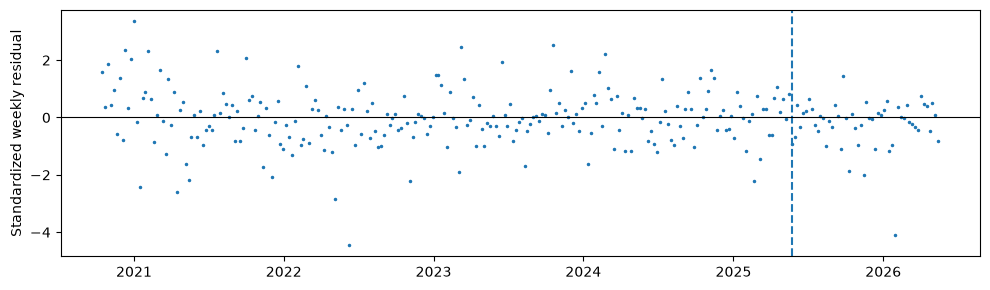

In [7]:
def block_indices(size, length, trials, seed):
    sampler = np.random.default_rng(seed)
    starts = sampler.integers(size, size=(trials, (size + length - 1) // length))
    return ((starts[:, :, None] + np.arange(length)) % size).reshape(trials, -1)[:, :size]


def paired_interval(values, length=4):
    idx = block_indices(len(values), length, 4000, SEED + 2)
    return np.quantile(np.asarray(values)[idx].mean(axis=1), [0.025, 0.975])


forecast_rows, contrasts = [], []
for name, pred in draws.items():
    lo, hi = np.quantile(pred, [0.1, 0.9], axis=1)
    written = plans[name].f.to_numpy() > 0
    forecast_rows.append({
        "model": name, "q80 pinball": pinball(pred, observed, .8).mean(),
        "q90 pinball": pinball(pred, observed, .9).mean(),
        "central 80% hits": ((lo <= observed) & (observed <= hi)).sum(),
        "expected strike exceedances on writes": plans[name].p_exceed[written].sum(),
        "observed strike exceedances on writes": (observed[written] > plans[name].q.to_numpy()[written]).sum(),
    })
for a, b in ((MODEL, BASE), (CHAIN, MODEL)):
    for label, values in (
        ("log growth", score[a] - score[b]),
        ("q80 pinball", pinball(draws[a], observed, .8) - pinball(draws[b], observed, .8)),
        ("q90 pinball", pinball(draws[a], observed, .9) - pinball(draws[b], observed, .9)),
    ):
        for block in (2, 4, 8) if label == "log growth" else (4,):
            low, high = paired_interval(values, block)
            contrasts.append({"comparison": f"{a} minus {b}", "measure": label, "block": block,
                              "mean": values.mean(), "95% low": low, "95% high": high})
display(pd.DataFrame(forecast_rows).set_index("model").round(5))
display(pd.DataFrame(contrasts).set_index(["comparison", "measure", "block"]).round(6))

limits = train[["rv30", "rv7"]].quantile([.25, .75]).to_numpy()
support = test[["rv30", "rv7"]].to_numpy()
central = np.all((support >= limits[0]) & (support <= limits[1]), axis=1)
loss = pinball(draws[MODEL], observed, .9)
display(pd.DataFrame([{"training-feature support": label, "weeks": mask.sum(),
                       "q90 pinball loss": loss[mask].mean() if mask.any() else np.nan}
                      for label, mask in [("both inside central 50%", central),
                                          ("at least one outside", ~central)]]).set_index("training-feature support"))

theta, z, _ = fitted[MODEL]
full_sample = pd.concat([train, test])
residuals = (full_sample.r.to_numpy() - theta[0]) / sigma_of(theta, full_sample, columns[MODEL])
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(full_sample.index, residuals, ".", ms=3)
ax.axvline(cutoff, color="tab:blue", ls="--")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Standardized weekly residual")
fig.tight_layout()
fig.savefig(FIG / "residuals_covered_call.png", dpi=150)
plt.show()

## Risks, break-even premiums and value of information

A rally above the strike reduces the BTC stack relative to holding. We apply deterministic rallies to representative inputs, with both trailing volatility features at their training medians. For each selected strike the **marginal Kelly break-even premium** equals the forecast expected payout plus the assumed cost. Below this amount every positive Kelly fraction has nonpositive expected log growth, by concavity. A position on a finite size grid may require a slightly higher premium. This is a forecast-based threshold per BTC covered.

The perfect-foresight calculation is a ceiling within the same strike grid, premiums and cost. It sees the realized return before choosing either full cover or holding. To estimate a more practical value of information, refit the same 30-plus-7-day model using only the most recent 120 training weeks and compare on the same holdout. This measures the value of that extra historical sample under the assumed premiums.

In [8]:
probe = train[["rv30", "d", "x", "fee"]].median().to_frame().T
_, _, probe_draws = forecast(train, probe, columns[MODEL])
probe_vol = probe.rv30.to_numpy()
probe_gross = premium(probe_vol)
probe_rows = []
for multiplier in cases:
    action = plan(probe_vol, probe_draws, prices=multiplier * probe_gross - COST).iloc[0]
    payout_draws = payout(action.q, probe_draws[0])
    probe_rows.append({"premium multiple": multiplier, "candidate strike above spot %": 100 * np.expm1(action.q),
                       "fraction": action.f, "gross premium sats": 1e8 * (action.prem + COST),
                       "break-even gross premium sats": 1e8 * (COST + payout_draws.mean()),
                       **{f"+{int(rally*100)}% spot rally, BTC gain %":
                          100 * action.f * (action.prem - payout(action.q, np.log1p(rally)))
                          for rally in (.10, .20, .30)}})
probe_table = pd.DataFrame(probe_rows).set_index("premium multiple")
display(probe_table.round(3))

# Even when the median probe holds, illustrate a committed at-the-money call.
forced_rally = 100 * (probe_gross[0, 0] - COST - payout(0, np.log1p(.20)))
print(f"Illustrative +20% rally, forced full ATM call at median pricing inputs: {forced_rally:+.2f}% BTC vs holding.")

oracle = np.log1p(np.maximum(0., (gross - COST - payout(Q[None, :], observed[:, None])).max(axis=1)))
_, _, short_draws = forecast(train.iloc[-120:], test, columns[MODEL])
short = plan(annual_vol, short_draws, prices=gross - COST)
short_score, _ = growth(test, short, short.f.to_numpy())
history_sats = 1e8 * (np.expm1(score[MODEL]) - np.expm1(short_score))
history_low, history_high = paired_interval(history_sats)
print(f"Foresight ceiling: {oracle.mean():.5f} log points/week. "
      f"240 vs 120 training weeks: {history_sats.mean():+,.0f} sats/BTC/week "
      f"(paired 95% interval {history_low:+,.0f} to {history_high:+,.0f}).")

,candidate strike above spot %,fraction,gross premium sats,break-even gross premium sats,"+10% spot rally, BTC gain %","+20% spot rally, BTC gain %","+30% spot rally, BTC gain %"
premium multiple,,,,,,,
0.8,21.531,0.0,11715.299,77871.629,0.000,0.000,-0.000
1.0,22.140,0.0,11939.428,65417.365,0.000,0.000,-0.000
1.2,0.000,1.0,3665525.458,3377814.239,-5.435,-13.011,-19.421


Illustrative +20% rally, forced full ATM call at median pricing inputs: -13.62% BTC vs holding.
Foresight ceiling: 0.01594 log points/week. 240 vs 120 training weeks: +0 sats/BTC/week (paired 95% interval +0 to +0).


## Model checks and decision uncertainty

The parameter recovery simulation resamples standardized shocks from the fitted training distribution and refits the original model with the same predictors. This checks recovery under the model's own assumptions. For sensitivity to the particular training sample, refit the model on four-week blocks, then inspect the median-input decision. Neither check accounts for uncertainty in market premiums.

In [9]:
trial_rng = np.random.default_rng(SEED + 1)
recovered = []
features = columns[MODEL]
for _ in range(150):
    simulated = train.assign(r=theta[0] + sigma_of(theta, train, features) * trial_rng.choice(z, len(z)))
    recovered.append(fit_scale(simulated, features))
display(pd.DataFrame({"target": theta, "recovered mean": np.mean(recovered, axis=0),
                      "simulation SD": np.std(recovered, axis=0)},
                     index=["drift", "intercept", "30-day", "7-day"]).round(5))

refit_fractions, refit_parameters = [], []
for idx in block_indices(len(train), 4, 200, SEED + 3):
    params, _, prediction = forecast(train.iloc[idx], probe, features)
    refit_parameters.append(params)
    refit_fractions.append(plan(probe_vol, prediction, prices=probe_gross - COST).f.iloc[0])
bounds = np.quantile(refit_parameters, [.025, .975], axis=0)
display(pd.DataFrame({"fit": theta, "block 95% low": bounds[0], "block 95% high": bounds[1]},
                     index=["drift", "intercept", "30-day", "7-day"]).round(5))
print(f"Median-input write frequency across training refits: {np.mean(np.asarray(refit_fractions)>0):.1%}")
print(f"Verified {len(fit_checks)} fits with maximum absolute gradient {max(fit_checks):.2g}")

,target,recovered mean,simulation SD
drift,0.00950,0.01045,0.00514
intercept,-1.63907,-1.68261,0.43250
30-day,0.40931,0.37725,0.24727
7-day,-0.07826,-0.06016,0.18608


,fit,block 95% low,block 95% high
drift,0.00950,-0.00341,0.02012
intercept,-1.63907,-2.54745,-0.88931
30-day,0.40931,-0.20338,0.92201
7-day,-0.07826,-0.42429,0.28522


Median-input write frequency across training refits: 30.5%
Verified 511 fits with maximum absolute gradient 1e-07


## Limitations

Black–Scholes premiums here are a shared spot-based scenario. Daily realized volatility does not identify the market's forward volatility, risk premium or strike-specific bid. A positive scenario can become negative after changing the premium or cost. The Friday midnight reference is a hypothetical settlement and these strikes are modeled as a grid. The empirical residual distribution has finite support, so it can give extreme rallies too little weight. One historical year does not validate a market edge. Further work would require authorized historical option bids, listed strikes and settlement prices, as well as evaluation over additional chronological regimes.

In [10]:
written = pl.f.to_numpy() > 0
losses = int(np.count_nonzero(score[MODEL][written] < 0))
total = lambda values: 100 * np.expm1(np.sum(values))
fmt = lambda value: f"{value:+.1f}%"
spread = score[MODEL] - score[BASE]
paired_low, paired_high = paired_interval(spread)
fee_sats = 1e8 * (np.expm1(score[CHAIN]) - np.expm1(score[MODEL]))
fee_low, fee_high = paired_interval(fee_sats)
results = {
    "weeks": n, "trades": int(written.sum()), "losses": losses,
    "model": fmt(total(score[MODEL])), "baseline": fmt(total(score[BASE])),
    "low_premium": fmt(total(cases[.8][1][MODEL])), "high_premium": fmt(total(cases[1.2][1][MODEL])),
    "worst": fmt(100 * np.expm1(score[MODEL].min()) + 0.0), "rally": fmt(forced_rally),
    "break_even_sats": f"{probe_table.loc[1.0, 'break-even gross premium sats']:,.0f}",
    "history": f"{history_sats.mean():+,.0f}",
    "history_low": f"{history_low:+,.0f}", "history_high": f"{history_high:+,.0f}",
    "holds": n - int(written.sum()),
    "q90_base": f"{pinball(draws[BASE], observed, .9).mean():.5f}",
    "q90_model": f"{pinball(draws[MODEL], observed, .9).mean():.5f}",
    "q90_fees": f"{pinball(draws[CHAIN], observed, .9).mean():.5f}",
    "fee_sats": f"{fee_sats.mean():+,.0f}",
    "fee_low": f"{fee_low:+,.0f}", "fee_high": f"{fee_high:+,.0f}",
    "gap_log": f"{spread.mean():+.6f}",
    "gap_low": f"{paired_low:+.6f}", "gap_high": f"{paired_high:+.6f}",
}
Path("_variables.yml").write_text(json.dumps({"spot": results}, indent=2) + "\n")
from IPython.display import Markdown
display(Markdown(
    "## Executive summary\n"
    f"- **Action.** The model wrote {results['trades']} of {n} calls after hypothetical costs.\n"
    f"- **Reason.** Compounded BTC gain versus holding was {results['model']} "
    f"versus {results['baseline']} for the 30-day baseline.\n"
    f"- **Risk.** It lost {losses} of its writes relative to holding. "
    f"A forced full ATM call in the illustrative 20% rally lost {results['rally']} relative to holding.\n"
    f"- **Value.** Adding 120 training weeks changed mean simple growth by "
    f"{results['history']} sats per BTC per week (95% interval {results['history_low']} to "
    f"{results['history_high']}). The separate fee feature changed weekly growth by "
    f"{results['fee_sats']} sats per BTC held (95% interval {results['fee_low']} to {results['fee_high']}). "
    "Historical bids could test the assumed premiums."
))

## Executive summary
- **Action.** The model wrote 5 of 52 calls after hypothetical costs.
- **Reason.** Compounded BTC gain versus holding was +12.0% versus +12.0% for the 30-day baseline.
- **Risk.** It lost 0 of its writes relative to holding. A forced full ATM call in the illustrative 20% rally lost -13.6% relative to holding.
- **Value.** Adding 120 training weeks changed mean simple growth by +0 sats per BTC per week (95% interval +0 to +0). The separate fee feature changed weekly growth by +193,095 sats per BTC held (95% interval -4,894 to +441,937). Historical bids could test the assumed premiums.

## Slide figures

Gains are expressed as actual simple or compounded BTC returns. The notebook writes both the chart PNGs and the reported figures used by Quarto. Data and graphics derived from the Coin Metrics Community archive are attributed under CC BY-NC 4.0.

In [11]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, NullLocator

INK, MUTED, GRID, PAPER = "#142638", "#526579", "#dbe4eb", "#f8fafc"
BLUE, TEAL, RED = "#155d9e", "#087e8b", "#b43240"
plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "font.family": "DejaVu Sans", "font.size": 12, "text.color": INK,
    "axes.labelcolor": MUTED, "axes.edgecolor": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
})


def save_chart(fig, name):
    fig.tight_layout(pad=1.0)
    fig.savefig(FIG / f"deck_{name}.png", dpi=180)
    plt.close(fig)

In [12]:
fig, ax = plt.subplots(figsize=(11.6, 3.25))
ax.plot(spot, color=MUTED, lw=1.15)
ax.axvspan(cutoff, spot.index.max(), color=BLUE, alpha=.09)
ax.plot(spot.loc[cutoff:], color=BLUE, lw=1.5)
ax.text(cutoff + (spot.index.max() - cutoff) / 2, 148_000, "52-week holdout",
        color=BLUE, ha="center", va="center", fontsize=11, weight="bold")
ax.set(yscale="log", ylim=(9_000, 168_000), xlim=(spot.index.min(), spot.index.max()))
ax.set_yticks([10_000, 20_000, 50_000, 100_000])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1_000:.0f}k"))
ax.yaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("BTC price (log scale)")
ax.grid(axis="y")
save_chart(fig, "title")

fig, ax = plt.subplots(figsize=(8.1, 3.5))
ax.hlines([0, 1], cutoff, test.end.max(), color=GRID, lw=1.1)
ax.scatter(test.index[~written], np.zeros((~written).sum()), color="#8193a3", s=20, zorder=3)
ax.scatter(test.index[written], np.ones(written.sum()), color=BLUE, s=67, zorder=3)
ax.set(yticks=[0, 1], yticklabels=["Held BTC", "Wrote call"], ylim=(-.45, 1.45))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
save_chart(fig, "action")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
comparison_names = [HOLD, BASE, MODEL]
bar_values = [total(score[name]) for name in comparison_names]
labels = ["Holding", "30-day volatility", "30-day + 7-day"]
bars = ax.barh(labels, bar_values, color=["#8193a3", TEAL, BLUE], height=.52)
for bar, value in zip(bars, bar_values):
    ax.text(value + .32, bar.get_y() + bar.get_height()/2,
            f"{value:+.1f}%" if value else "0.0%", va="center", weight="bold")
ax.invert_yaxis()
ax.set(xlim=(0, max(bar_values) + 3.2), xlabel="52-week BTC gain versus holding")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x")
save_chart(fig, "reason")

fig, ax = plt.subplots(figsize=(7.6, 3.4))
scenario_values = [total(cases[m][1][MODEL]) for m in (.8, 1., 1.2)]
bars = ax.barh(["20% lower", "Main scenario", "20% higher"], scenario_values,
               color=["#9dbfdd", BLUE, TEAL], height=.52)
for bar, value in zip(bars, scenario_values):
    ax.text(value + .33, bar.get_y() + bar.get_height()/2, f"{value:+.1f}%", va="center", weight="bold")
ax.invert_yaxis()
ax.set(xlim=(0, max(scenario_values) + 4.), xlabel="52-week BTC gain versus holding")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x")
save_chart(fig, "risk")

fig, ax = plt.subplots(figsize=(8.65, 3.35))
point = fee_sats.mean() / 1000
low, high = fee_low / 1000, fee_high / 1000
ax.axvspan(min(-75, low-20), 0, color=RED, alpha=.06)
ax.axvline(0, color=MUTED, lw=1.2, ls="--")
ax.text(7, .34, "Zero gain", ha="left", color=MUTED, fontsize=11)
ax.hlines(0, low, high, color=BLUE, lw=3)
ax.vlines([low, high], -.044, .044, color=BLUE, lw=2)
ax.scatter([point], [0], color=BLUE, s=105, zorder=3)
ax.text(point, .13, f"{point:+.0f}k estimate", ha="center", color=BLUE, weight="bold")
ax.text(low - 3, -.13, f"{low:+.0f}k", ha="right", color=MUTED)
ax.text(high, -.13, f"{high:+.0f}k", ha="center", color=MUTED)
ax.set(xlim=(min(-75, low-20), max(480, high+40)), ylim=(-.28, .48), yticks=[],
       xlabel="Extra sats per BTC held per week with the fee feature")
ax.set_xticks([0, 100, 200, 300, 400])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}k" if v else "0"))
ax.spines["left"].set_visible(False)
save_chart(fig, "value")